In [24]:
import numpy as np
import matplotlib.pyplot as plt
from ase.io import write
from ase.visualize import view
from arcskin.make_neb_endpoints import make_endpoints
import pandas as pd

possible_paths = {
    0: {
        "reactants": ["[O][N][O]", "O=S=O"],
        "products": ["O=S(=O)=O", "[N]=O"],
        "reactants_energies": [-5582.146620059146, -14933.34580738717],
        "products_energies": [-16980.83054728788, -3535.176241480919],
        "diff": np.float64(-0.5143613224827277),
    }
}


In [25]:
pd.DataFrame(possible_paths).T

,reactants,products,reactants_energies,products_energies,diff
0,"[[O][N][O], O=S=O]","[O=S(=O)=O, [N]=O]","[-5582.14662, -14933.345807]","[-16980.830547, -3535.176241]",-0.514361


In [28]:
reactants, products = make_endpoints(
    possible_paths[0]["reactants"], possible_paths[0]["products"], shift=1.3
)


[O][N][O] + O=S=O -> O=S(=O)=O + [N]=O | form: ['O0-S4']  break: ['O0-N1']


In [29]:
pd.DataFrame([reactants.info,products.info],index=["reactants","products"]).T

,reactants,products
charge,0,0
mult,2,2
n_radicals,3,1
smiles,"[[O][N][O], O=S=O]","[O=S(=O)=O, [N]=O]"
formed,"[(0, 4)]","[(0, 4)]"
broken,"[(0, 1)]","[(0, 1)]"


In [30]:
view(reactants,viewer="x3d")

In [31]:
view(products,viewer="x3d")

In [32]:
from arcskin.make_neb_endpoints import make_endpoints


reaction_endpoints = {}
for k,v in possible_paths.items():
    try:
        reactants, products = make_endpoints(v["reactants"],v["products"],shift=1.5)
        reaction_endpoints[k] = {
                "reactants":reactants,
                "products":products,
                "overall":possible_paths[k]
                                     }
    except Exception:
        print(f"{k} failed")
        pass

[O][N][O] + O=S=O -> O=S(=O)=O + [N]=O | form: ['O0-S4']  break: ['O0-N1']


In [33]:
from arcskin.run_neb import run_all

results = run_all(reaction_endpoints,n_images=16,climb=True)


running with aimnet


In [34]:
results

,Ea,dE,reactants,products,reactants_energies,products_energies,diff,images,nebfit,sane
0,1.065734,0.144609,"[[O][N][O], O=S=O]","[O=S(=O)=O, [N]=O]","[-5582.14662, -14933.345807]","[-16980.830547, -3535.176241]",-0.514361,"[{'numbers': [8, 7, 8, 8, 16, 8], 'positions':...","{'path': [0, '0.132289', '0.257407', '0.379947...",True


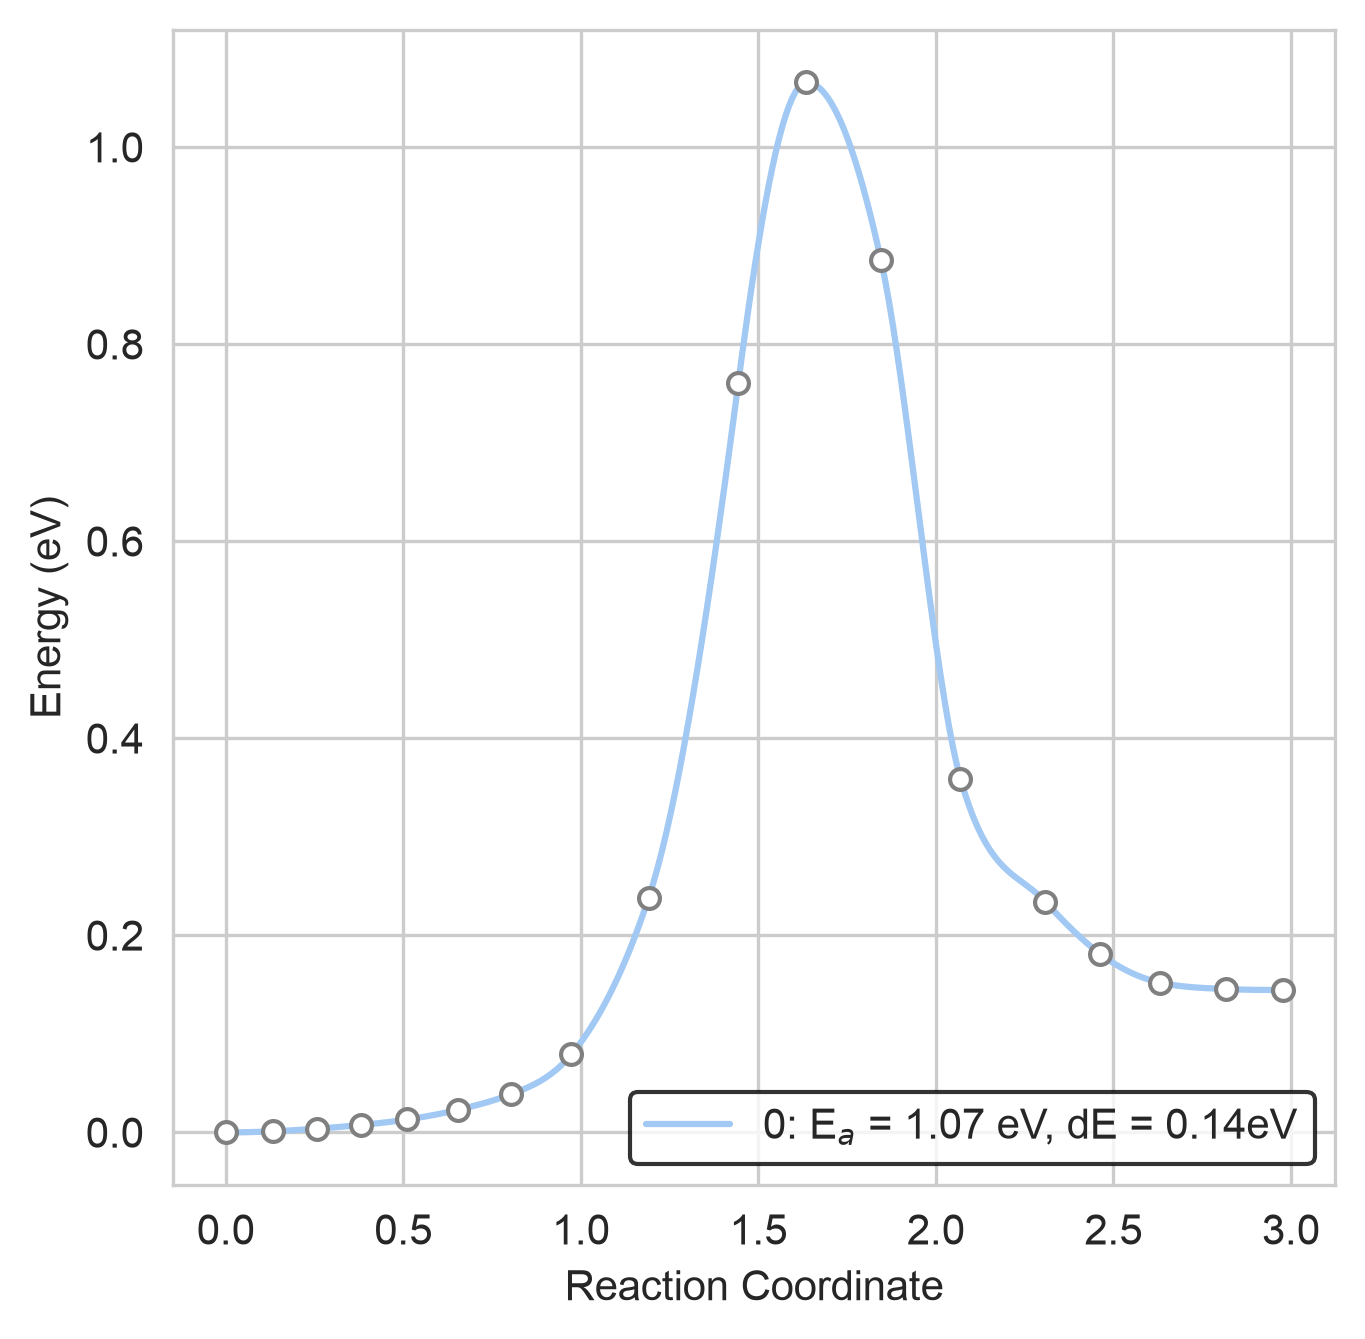

In [35]:
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import collections 

sns.set_style('whitegrid')
sns.set_palette('pastel')

def plot_nebruns(image_dict,ax,**kws):
    for k,v in image_dict.items():
        if v["sane"]:
            fit = v["nebfit"]
            Ef = fit["energies"].max()
            ax.plot(fit["fit_path"],fit["fit_energies"],label=f'{k}: E$_a$ = {Ef :.2F} eV, dE = {v["dE"]:.2F}eV')
            ax.plot(fit["path"],fit["energies"],**kws)

kws = {'marker':'o',
       'linestyle':'None',
       'color':'grey',
       'markerfacecolor':'white',
       'markersize':5}

fig,ax = plt.subplots(ncols=1,nrows=1,figsize=(5,5),dpi=300,sharey=True,sharex=True)
plot_nebruns(image_dict=results.T,ax=ax,**kws)
ax.set_ylabel('Energy (eV)')
ax.set_xlabel('Reaction Coordinate')
    #flat_ax[i].set_title(f"expansion={nebbys[i]["expansion"]},rattle={nebbys[i]["rattle"]},nimages={nebbys[i]["nimages"]}")
ax.legend(edgecolor="black")

In [36]:
from ase.visualize import view 
from ase.atoms import Atoms 

view(
    [
        Atoms.fromdict(i) for i in results["images"][0]
    ],
    viewer="ngl"
)

In [37]:
from monty.serialization import dumpfn 

dumpfn(results,"results.json")